# Formative 2 — Human Activity Recognition with a Hidden Markov Model
**Name:** Mahlet Tilahun 


**Pipeline:** CSV recordings → resample to 50 Hz → 2 s windows → time + frequency features → z-score → Gaussian HMM (supervised init → Baum–Welch) → Viterbi decoding → evaluation on unseen recordings.
**Native sampling rate:** 62.4 Hz (resampled to 50 Hz)



In [1]:
import os, re, glob, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# CONFIG 
ACTIVITIES = ["standing", "walking", "jumping", "still"]   # hidden states Z
SENSOR_COLS = ["ax", "ay", "az", "gx", "gy", "gz"]
TARGET_FS  = 50          # Hz – every recording is resampled to this common rate
WIN_SEC    = 2.0         # window length in seconds
OVERLAP    = 0.5         # 50 % overlap
WIN  = int(WIN_SEC * TARGET_FS)           # samples per window (100)
STEP = int(WIN * (1 - OVERLAP))           # hop (50)
DATA_DIR, FIG_DIR = "data", "figures"
os.makedirs(FIG_DIR, exist_ok=True)
print(f"Window = {WIN} samples ({WIN_SEC}s), hop = {STEP} samples, frequency resolution = {1/WIN_SEC} Hz, Nyquist = {TARGET_FS/2} Hz")

Window = 100 samples (2.0s), hop = 50 samples, frequency resolution = 0.5 Hz, Nyquist = 25.0 Hz


## 1. Data layout
```
data/train/  standing_01.csv, walking_01.csv, ...   single activity, label taken from the file name
             seq_01.csv, ...                        chained activities, per-row `label` column
data/test/   seq_01.csv, seq_02.csv                 never used in training
```
Columns: `time` (s), `ax, ay, az` (accelerometer incl. gravity, m/s²), `gx, gy, gz` (gyroscope, rad/s).

**Why chained "seq" files?** Single-activity files only contain self-transitions (walking → walking), so **A** could not learn activity changes. `scripts/make_sequences.py` joins clips in realistic orders (e.g. still → standing → walking → jumping) with a per-row label. The joins are idealised: real changes between activities are smoother.

### 1a. Converting Sensor Logger exports
Uses `TotalAcceleration.csv` (with gravity; `Accelerometer.csv` has gravity removed) and `Gyroscope.csv`, aligns them on one clock, trims the start/end (screen-tap noise) and writes a clean CSV.

In [2]:
def sensor_logger_to_csv(folder, out_csv, label=None, fs=TARGET_FS, trim=0.5, acc_scale=1.0):
    """Merge Accelerometer.csv + Gyroscope.csv from a Sensor Logger export into one clean CSV.
    acc_scale: multiply accel by this (e.g. 9.81 if your phone logs in g, so the data are in m/s^2)."""
    # Prefer TotalAcceleration.csv (includes gravity); Accelerometer.csv on many Android phones has gravity removed
    acc_name = "TotalAcceleration.csv" if os.path.exists(os.path.join(folder, "TotalAcceleration.csv")) else "Accelerometer.csv"
    acc = pd.read_csv(os.path.join(folder, acc_name))
    gyr = pd.read_csv(os.path.join(folder, "Gyroscope.csv"))
    t0 = max(acc.seconds_elapsed.min(), gyr.seconds_elapsed.min()) + trim
    t1 = min(acc.seconds_elapsed.max(), gyr.seconds_elapsed.max()) - trim
    t = np.arange(t0, t1, 1 / fs)
    out = {"time": t - t0}
    for df, pre, sc in ((acc, "a", acc_scale), (gyr, "g", 1.0)):
        for ax in "xyz":
            out[pre + ax] = np.interp(t, df.seconds_elapsed, df[ax] * sc)
    out = pd.DataFrame(out)
    if label: out["label"] = label
    out.to_csv(out_csv, index=False)
    return out
# Example:  sensor_logger_to_csv("raw/walk_01", "data/train/walking_01.csv", acc_scale=1.0)

In [3]:
# Sanity check: the data folders must exist and contain CSV files
for split in ("train", "test"):
    n = len(glob.glob(f"{DATA_DIR}/{split}/*.csv"))
    assert n > 0, f"No CSV files found in {DATA_DIR}/{split}/ - run scripts/convert_all.py and scripts/make_sequences.py first (see README)."
    print(f"{DATA_DIR}/{split}: {n} CSV files")

data/train: 57 CSV files
data/test: 2 CSV files


## 2. Loading and harmonising sampling rates
Every clip is linearly interpolated onto a uniform 50 Hz grid. The phone's native rate (62.4 Hz, measured before resampling) is reported below.

In [4]:
def load_recording(path):
    df = pd.read_csv(path).rename(columns={"timestamp": "time"})
    t = df["time"].values.astype(float)
    fs_raw = 1 / np.median(np.diff(t))
    t_new = np.arange(t[0], t[-1], 1 / TARGET_FS)
    sig = np.column_stack([np.interp(t_new, t, df[c].values) for c in SENSOR_COLS])
    if "label" in df.columns:
        idx = np.clip(np.searchsorted(t, t_new), 0, len(t) - 1)
        lab = df["label"].values[idx]
    else:
        name = os.path.basename(path).lower()
        act = next(a for a in ACTIVITIES if name.startswith(a))
        lab = np.array([act] * len(t_new))
    return sig, lab, fs_raw

def load_split(split):
    recs, rows = [], []
    for p in sorted(glob.glob(f"{DATA_DIR}/{split}/*.csv")):
        sig, lab, fs_raw = load_recording(p)
        recs.append(dict(name=os.path.basename(p), sig=sig, lab=lab))
        rows.append(dict(file=os.path.basename(p), native_fs_hz=round(fs_raw, 1), seconds=round(len(sig)/TARGET_FS, 1)))
    return recs, pd.DataFrame(rows)

train_recs, train_info = load_split("train")
test_recs,  test_info  = load_split("test")
print(f"{len(train_recs)} training files, {len(test_recs)} test files")
print("\nNative sampling rate of recordings:")
display(train_info.assign(native_fs_hz=train_info.native_fs_hz.round(0)).groupby("native_fs_hz").agg(files=("file","count"), total_seconds=("seconds","sum")))
_rate_file = os.path.join("data", "sampling_rates.csv")      # written by scripts/convert_all.py (real rate BEFORE resampling to 50 Hz)
if os.path.exists(_rate_file):
    _r = pd.read_csv(_rate_file)
    print(f"\nNative phone sampling rate measured before resampling: {_r.native_fs_hz.mean():.1f} Hz (min {_r.native_fs_hz.min():.1f}, max {_r.native_fs_hz.max():.1f})")
print("\nSeconds of data per activity, original single clips only:")
secs = {a: sum((r["lab"] == a).sum() for r in train_recs if not r["name"].startswith("seq")) / TARGET_FS for a in ACTIVITIES}
display(pd.Series(secs, name="seconds").round(1))

57 training files, 2 test files

Native sampling rate of recordings:


,files,total_seconds
native_fs_hz,,
50.0,57,691.7



Native phone sampling rate measured before resampling: 62.4 Hz (min 62.3, max 62.4)

Seconds of data per activity, original single clips only:


standing    111.7
walking     102.3
jumping      92.1
still       104.8
Name: seconds, dtype: float64

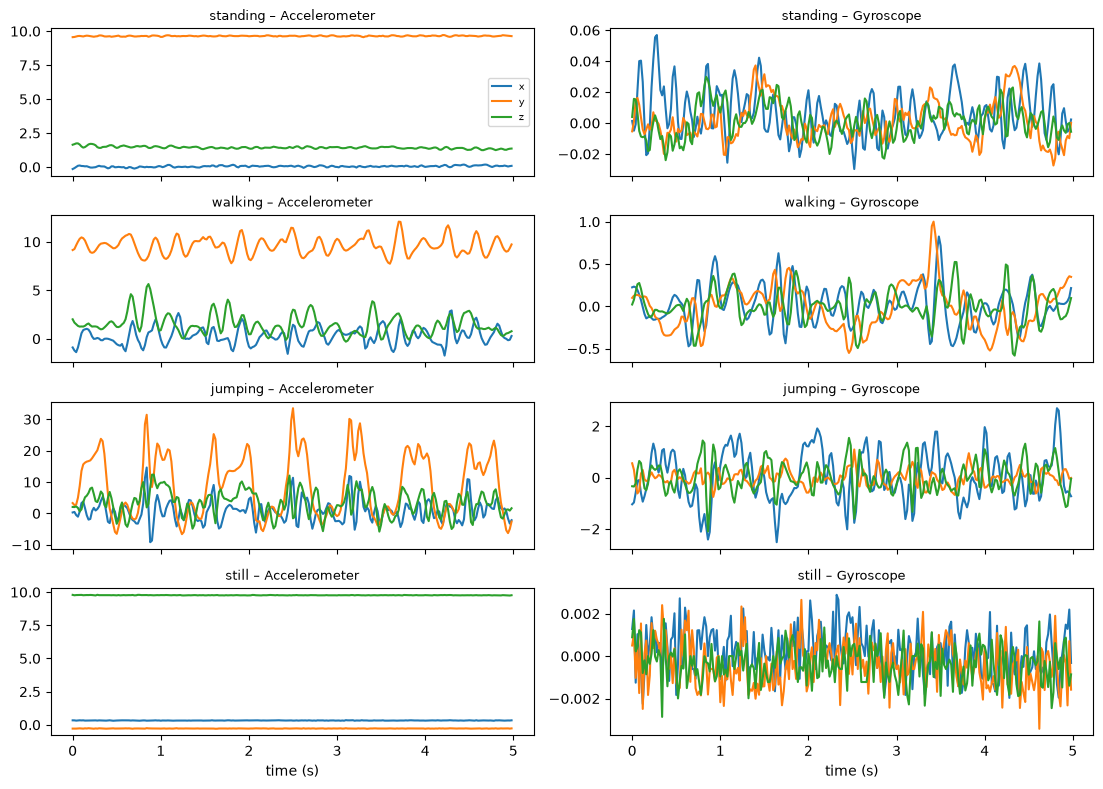

In [5]:
# Visualise raw samples 
fig, axs = plt.subplots(len(ACTIVITIES), 2, figsize=(11, 8), sharex=True)
for i, a in enumerate(ACTIVITIES):
    r = next(r for r in train_recs if r["name"].startswith(a))
    t = np.arange(len(r["sig"])) / TARGET_FS
    for j, (cols, ttl) in enumerate(((slice(0,3), "Accelerometer"), (slice(3,6), "Gyroscope"))):
        axs[i, j].plot(t[:250], r["sig"][:250, cols])
        axs[i, j].set_title(f"{a} – {ttl}", fontsize=9)
axs[-1, 0].set_xlabel("time (s)"); axs[-1, 1].set_xlabel("time (s)")
axs[0, 0].legend(["x","y","z"], fontsize=7); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/raw_samples.png", dpi=150); plt.show()

## 3. Windowing and feature extraction
**Window:** 2 s × 50 Hz = 100 samples, 50 % overlap (1 s hop). A window covers several walking steps, gives 0.5 Hz FFT resolution (enough to separate walking ≈ 3.3 Hz from jumping ≈ 1.3 Hz, both measured in my data), and the overlap doubles the number of observations. The 25 Hz Nyquist limit is far above human movement (< 10 Hz).

**Features (24 per window):**

| Feature(s) | Domain | Distinguishes |
|---|---|---|
| accel mean x, y, z | time | phone orientation: gravity on z (still) vs. y (standing) |
| accel / gyro std x, y, z | time | amount of movement: still < standing < walking < jumping |
| SMA (accel, gyro) | time | overall movement intensity |
| corr(ax,ay), (ax,az), (ay,az) | time | coordination between axes |
| accel-magnitude mean / std / range; gyro-magnitude mean / std | time | rotation-independent intensity; jump impacts give a huge range |
| dominant frequency (accel, gyro magnitude), FFT | frequency | rhythm: walking ≈ 3.3 Hz, jumping ≈ 1.3 Hz, still/standing none |
| spectral energy (accel, gyro), FFT | frequency | strength of the rhythm |
| spectral entropy (accel), FFT | frequency | periodic (low) vs. noise-like (high) |

**Normalisation:** z-score fitted on training data only. Std, energy, range and SMA span about three orders of magnitude (0.011 m/s² still → ≈ 8 jumping), so they are log-transformed first; this suits Gaussian emissions.

In [6]:
def spectral(sig):
    x = sig - sig.mean()
    P = np.abs(np.fft.rfft(x * np.hanning(len(x)))) ** 2 / len(x)
    f = np.fft.rfftfreq(len(x), 1 / TARGET_FS)
    energy = P.sum()
    dom = f[1:][P[1:].argmax()] if energy > 1e-12 else 0.0
    p = P / (energy + 1e-12)
    entropy = -np.sum(p * np.log(p + 1e-12)) / np.log(len(p))
    return dom, energy, entropy

FEATURE_NAMES = (["acc_mean_x","acc_mean_y","acc_mean_z","acc_std_x","acc_std_y","acc_std_z","gyr_std_x","gyr_std_y","gyr_std_z",
                  "acc_sma","gyr_sma","acc_corr_xy","acc_corr_xz","acc_corr_yz",
                  "accmag_mean","accmag_std","accmag_range","gyrmag_mean","gyrmag_std",
                  "acc_dom_freq","acc_energy","acc_entropy","gyr_dom_freq","gyr_energy"])
LOG_IDX = [i for i, n in enumerate(FEATURE_NAMES) if any(k in n for k in ("std", "energy", "range", "gyrmag_mean", "sma"))]

def extract_features(w):
    acc, gyr = w[:, :3], w[:, 3:]
    am, gm = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    c = np.nan_to_num(np.corrcoef(acc.T))
    ad, ae, aent = spectral(am); gd, ge, _ = spectral(gm)
    f = [*acc.mean(0), *acc.std(0), *gyr.std(0),
         np.abs(acc).sum(1).mean(), np.abs(gyr).sum(1).mean(),
         c[0, 1], c[0, 2], c[1, 2],
         am.mean(), am.std(), np.ptp(am), gm.mean(), gm.std(),
         ad, ae, aent, gd, ge]
    f = np.array(f, float)
    f[LOG_IDX] = np.log(f[LOG_IDX] + 1e-3)
    return f

def featurize(rec):
    X, y = [], []
    for s in range(0, len(rec["sig"]) - WIN + 1, STEP):
        X.append(extract_features(rec["sig"][s:s + WIN]))
        labs, cnt = np.unique(rec["lab"][s:s + WIN], return_counts=True)
        y.append(labs[cnt.argmax()])                      # majority label inside the window
    return np.array(X), np.array(y)

train_raw = [featurize(r) for r in train_recs]
test_raw  = [featurize(r) for r in test_recs]
allX = np.vstack([x for x, _ in train_raw])
MU, SD = allX.mean(0), allX.std(0) + 1e-8                 # z-score statistics from TRAIN only
zs = lambda X: (X - MU) / SD
X_train = [zs(x) for x, _ in train_raw]; y_train = [y for _, y in train_raw]
X_test  = [zs(x) for x, _ in test_raw];  y_test  = [y for _, y in test_raw]
print("Feature vector size:", X_train[0].shape[1], "| train windows:", sum(len(y) for y in y_train), "| test windows:", sum(len(y) for y in y_test))

Feature vector size: 24 | train windows: 608 | test windows: 106


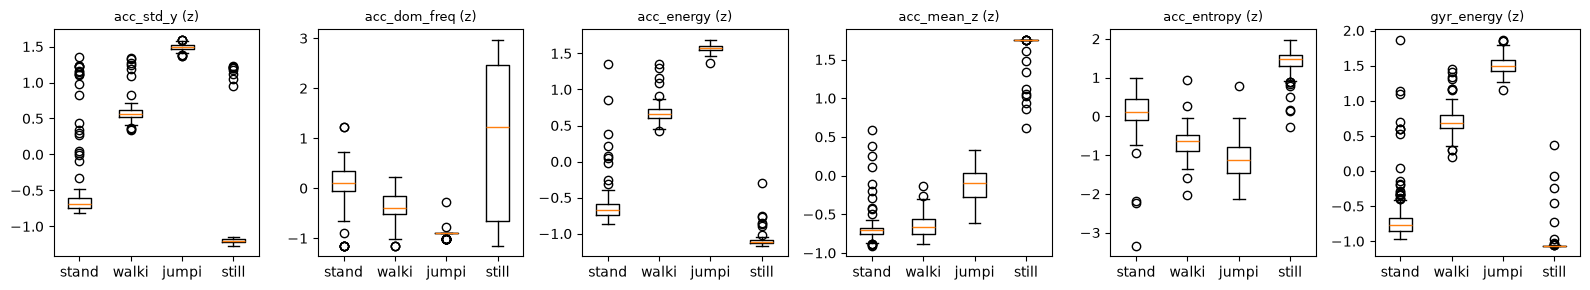

In [7]:
# Feature separability plot 
Xa, ya = np.vstack(X_train), np.concatenate(y_train)
show = ["acc_std_y", "acc_dom_freq", "acc_energy", "acc_mean_z", "acc_entropy", "gyr_energy"]
fig, axs = plt.subplots(1, len(show), figsize=(16, 3))
for ax, n in zip(axs, show):
    k = FEATURE_NAMES.index(n)
    ax.boxplot([Xa[ya == a, k] for a in ACTIVITIES]); ax.set_xticklabels([a[:5] for a in ACTIVITIES]); ax.set_title(n + " (z)", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/feature_boxplots.png", dpi=150); plt.show()

## 4. HMM components
| Element | Definition here |
|---|---|
| Hidden states **Z** | 4 activities: standing, walking, jumping, still |
| Observations **X** | 24-D z-scored feature vector per 2 s window |
| Initial probs **π** | share of sequences starting in each activity (+ smoothing) |
| Transition matrix **A** | 4×4, counted from consecutive labelled windows (+ Laplace smoothing), refined by Baum–Welch |
| Emission probs **B** | one diagonal-covariance Gaussian per state: N(x; μ, σ²) |

## 5. Algorithms 
* **Viterbi** decodes the most probable activity sequence. The metrics compare one predicted label per window with the truth, so Viterbi feeds the evaluation directly.
* **Baum–Welch (EM)** learns π, A, μ, σ² by maximising the training likelihood. Stops when |ΔlogL| / N < 10⁻⁴ (log-likelihood from the forward algorithm).
* **Supervised initialisation** from label counts anchors each state to a real activity; Baum–Welch then refines it.

In [8]:
def logsumexp(a, axis=None):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))
    return out.item() if axis is None else np.squeeze(out, axis=axis)

class GaussianHMM:
    """HMM with diagonal-Gaussian emissions, implemented in log-space with NumPy only."""
    def __init__(self, states, n_features, var_floor=1e-2, smooth=1.0):
        self.states, self.K, self.D = list(states), len(states), n_features
        self.var_floor, self.smooth = var_floor, smooth

    #  parameter estimation from labelled data 
    def fit_supervised(self, X_list, y_list):
        idx = {s: i for i, s in enumerate(self.states)}
        A = np.full((self.K, self.K), self.smooth); pi = np.full(self.K, self.smooth)
        Y = [np.array([idx[s] for s in y]) for y in y_list]
        for yi in Y:
            pi[yi[0]] += 1
            for a, b in zip(yi[:-1], yi[1:]): A[a, b] += 1
        self.pi, self.A = pi / pi.sum(), A / A.sum(1, keepdims=True)
        Xall, Yall = np.vstack(X_list), np.concatenate(Y)
        self.mu = np.array([Xall[Yall == k].mean(0) for k in range(self.K)])
        self.var = np.array([Xall[Yall == k].var(0) + self.var_floor for k in range(self.K)])
        return self

    #  emissions 
    def _log_emission(self, X):
        d = X[:, None, :] - self.mu[None]                          # (T,K,D)
        return -0.5 * np.sum(np.log(2 * np.pi * self.var)[None] + d ** 2 / self.var[None], axis=2)

    #  forward / backward 
    def _forward(self, logB):
        T, logA = len(logB), np.log(self.A)
        la = np.zeros((T, self.K)); la[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logB[t] + logsumexp(la[t - 1][:, None] + logA, axis=0)
        return la

    def _backward(self, logB):
        T, logA = len(logB), np.log(self.A)
        lb = np.zeros((T, self.K))
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None], axis=1)
        return lb

    def log_likelihood(self, X):
        return logsumexp(self._forward(self._log_emission(X))[-1])

    # Viterbi decoding
    def viterbi(self, X):
        logB, logA = self._log_emission(X), np.log(self.A)
        T = len(X); delta = np.zeros((T, self.K)); psi = np.zeros((T, self.K), int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            sc = delta[t - 1][:, None] + logA
            psi[t], delta[t] = sc.argmax(0), sc.max(0) + logB[t]
        path = np.zeros(T, int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1): path[t] = psi[t + 1, path[t + 1]]
        return np.array(self.states)[path]

    def predict_framewise(self, X):                                 # baseline: ignore transitions
        return np.array(self.states)[self._log_emission(X).argmax(1)]

    # Baum-Welch (EM) 
    def baum_welch(self, X_list, tol=1e-4, max_iter=200, verbose=True):
        """Stops when |ΔlogL| / n_observations < tol (a proper convergence check), or at max_iter."""
        hist, n_obs = [], sum(len(x) for x in X_list)
        for it in range(max_iter):
            logA = np.log(self.A)
            pi_a = np.zeros(self.K); A_n = np.zeros((self.K, self.K)); gs = np.zeros(self.K)
            gx = np.zeros((self.K, self.D)); gxx = np.zeros((self.K, self.D)); LL = 0.0
            for X in X_list:                                        # E-step
                logB = self._log_emission(X); la, lb = self._forward(logB), self._backward(logB)
                ll = logsumexp(la[-1]); LL += ll
                gamma = np.exp(la + lb - ll)
                if len(X) > 1:
                    xi = np.exp(la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll)
                    A_n += xi.sum(0)
                pi_a += gamma[0]; gs += gamma.sum(0); gx += gamma.T @ X; gxx += gamma.T @ (X ** 2)
            hist.append(LL)
            self.pi = (pi_a + 1e-3) / (pi_a + 1e-3).sum()           # M-step
            A_n += 1e-2; self.A = A_n / A_n.sum(1, keepdims=True)
            self.mu = gx / (gs[:, None] + 1e-10)
            self.var = np.maximum(gxx / (gs[:, None] + 1e-10) - self.mu ** 2, self.var_floor)
            if verbose and it % 5 == 0: print(f"iter {it:3d}  logL = {LL:10.2f}")
            if it > 0 and abs(hist[-1] - hist[-2]) / n_obs < tol:
                if verbose: print(f"Converged at iteration {it} (|ΔlogL|/N = {abs(hist[-1]-hist[-2])/n_obs:.2e} < {tol})")
                break
        return hist

## 6. Training

iter   0  logL =     631.39
iter   5  logL =    3690.15
Converged at iteration 5 (|ΔlogL|/N = 7.48e-16 < 0.0001)


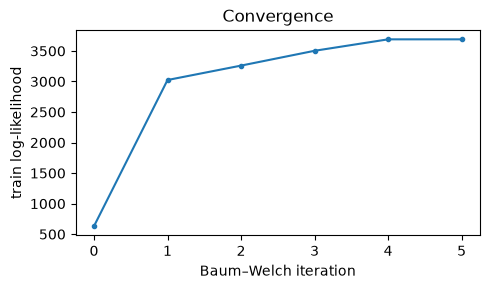

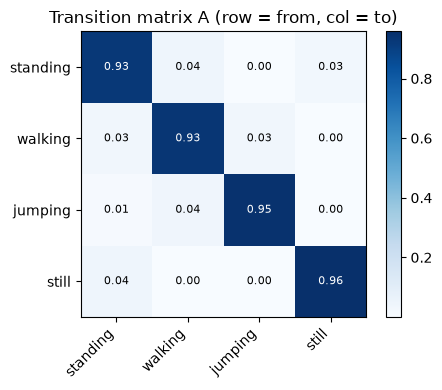

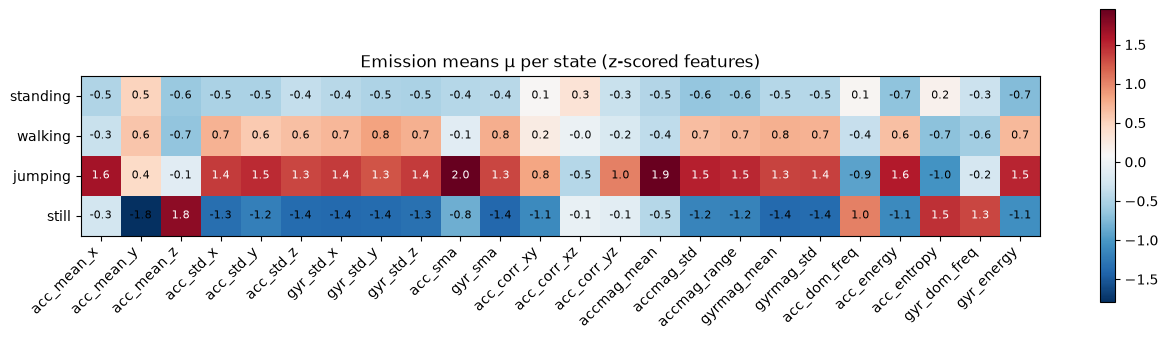

Initial probabilities π: {'standing': np.float64(0.263), 'walking': np.float64(0.228), 'jumping': np.float64(0.228), 'still': np.float64(0.281)}


In [9]:
hmm_sup = GaussianHMM(ACTIVITIES, len(FEATURE_NAMES)).fit_supervised(X_train, y_train)   # counts + per-state Gaussians
hmm = copy.deepcopy(hmm_sup)
history = hmm.baum_welch(X_train, tol=1e-4, max_iter=200)

plt.figure(figsize=(5, 3)); plt.plot(history, marker="o", ms=3); plt.xlabel("Baum–Welch iteration"); plt.ylabel("train log-likelihood")
plt.title("Convergence"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/bw_convergence.png", dpi=150); plt.show()

def heatmap(M, xl, yl, title, fname, fmt="{:.2f}", figsize=(5, 4), cmap="Blues"):
    fig, ax = plt.subplots(figsize=figsize); im = ax.imshow(M, cmap=cmap)
    ax.set_xticks(range(len(xl))); ax.set_xticklabels(xl, rotation=45, ha="right"); ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]): ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=8, color="black" if M[i, j] < M.max()*.6 else "white")
    ax.set_title(title); plt.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{fname}", dpi=150); plt.show()

heatmap(hmm.A, ACTIVITIES, ACTIVITIES, "Transition matrix A (row = from, col = to)", "transition_heatmap.png")
heatmap(hmm.mu, FEATURE_NAMES, ACTIVITIES, "Emission means μ per state (z-scored features)", "emission_means.png", fmt="{:.1f}", figsize=(13, 3.5), cmap="RdBu_r")
print("Initial probabilities π:", dict(zip(ACTIVITIES, hmm.pi.round(3))))

## 7. Evaluation on unseen recordings
**Test data:** 12 clips (3 per activity) recorded after training at a different location, with more vigorous walking and jumping than in training. They were joined into 2 chained files (106 windows) and were never used for normalisation, parameter estimation or model selection.

,State (Activity),Number of Samples,Sensitivity,Specificity,Per-class Accuracy,Overall Accuracy
0,standing,42,0.905,0.938,0.925,0.896
1,walking,24,0.875,0.951,0.934,0.896
2,jumping,13,1.000,0.968,0.972,0.896
3,still,27,0.852,1.000,0.962,0.896


HMM + Baum-Welch (Viterbi) – TRAIN                 0.965
HMM + Baum-Welch (Viterbi) – TEST                  0.896
Supervised-only HMM (Viterbi) – TEST               0.934
No-transition baseline (argmax emission) – TEST    0.896
Name: accuracy, dtype: float64

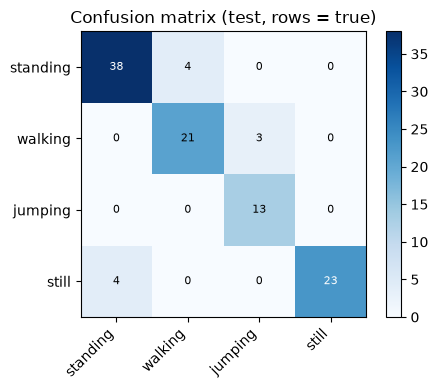

In [10]:
def confusion(y_true, y_pred, classes):
    cm = np.zeros((len(classes), len(classes)), int); ix = {c: i for i, c in enumerate(classes)}
    for t, p in zip(y_true, y_pred): cm[ix[t], ix[p]] += 1
    return cm

def metrics_table(cm, classes):
    N, rows = cm.sum(), []
    for i, c in enumerate(classes):
        TP = cm[i, i]; FN = cm[i].sum() - TP; FP = cm[:, i].sum() - TP; TN = N - TP - FN - FP
        rows.append({"State (Activity)": c, "Number of Samples": int(cm[i].sum()),
                     "Sensitivity": TP / (TP + FN) if TP + FN else np.nan,
                     "Specificity": TN / (TN + FP) if TN + FP else np.nan,
                     "Per-class Accuracy": (TP + TN) / N, "Overall Accuracy": np.trace(cm) / N})
    return pd.DataFrame(rows)

def evaluate(model, X_list, y_list, decoder="viterbi"):
    yt = np.concatenate(y_list)
    yp = np.concatenate([model.viterbi(X) if decoder == "viterbi" else model.predict_framewise(X) for X in X_list])
    return yt, yp

yt, yp = evaluate(hmm, X_test, y_test)
cm = confusion(yt, yp, ACTIVITIES)
table = metrics_table(cm, ACTIVITIES)
display(table.round(3))

# comparison: train vs test, supervised-only vs Baum-Welch, HMM vs frame-by-frame (no transitions)
comp = {"HMM + Baum-Welch (Viterbi) – TRAIN": np.mean(np.concatenate([hmm.viterbi(X) for X in X_train]) == np.concatenate(y_train)),
        "HMM + Baum-Welch (Viterbi) – TEST":  np.mean(yp == yt),
        "Supervised-only HMM (Viterbi) – TEST": np.mean(np.array(evaluate(hmm_sup, X_test, y_test)[1]) == yt),
        "No-transition baseline (argmax emission) – TEST": np.mean(evaluate(hmm, X_test, y_test, "frame")[1] == yt)}
display(pd.Series(comp, name="accuracy").round(3))

heatmap(cm, ACTIVITIES, ACTIVITIES, "Confusion matrix (test, rows = true)", "confusion_matrix.png", fmt="{:d}")

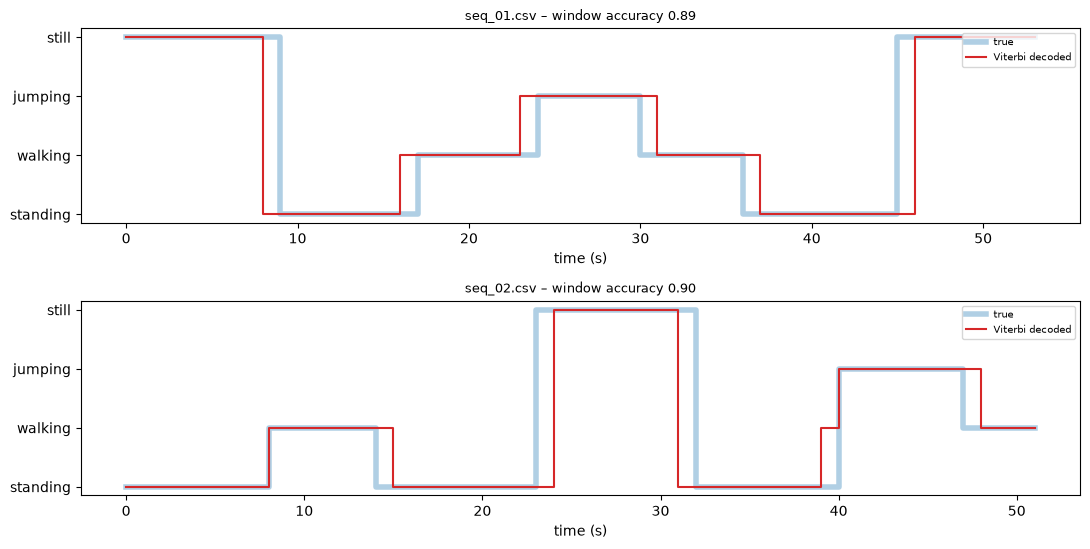

In [11]:
# Decoded sequences: truth vs prediction for each test file
ix = {a: i for i, a in enumerate(ACTIVITIES)}
fig, axs = plt.subplots(len(X_test), 1, figsize=(11, 2.8 * len(X_test)), squeeze=False)
for k, (X, y) in enumerate(zip(X_test, y_test)):
    pred = hmm.viterbi(X); t = np.arange(len(y)) * STEP / TARGET_FS; ax = axs[k, 0]
    ax.step(t, [ix[v] for v in y], where="post", lw=4, alpha=.35, label="true")
    ax.step(t, [ix[v] for v in pred], where="post", lw=1.5, color="C3", label="Viterbi decoded")
    ax.set_yticks(range(len(ACTIVITIES))); ax.set_yticklabels(ACTIVITIES); ax.set_xlabel("time (s)")
    ax.set_title(f"{test_recs[k]['name']} – window accuracy {np.mean(pred == y):.2f}", fontsize=9); ax.legend(loc="upper right", fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/decoded_sequences.png", dpi=150); plt.show()

In [12]:
# Train vs test feature-space check and emission-covariance summary
print("Most confused pair(s) (true -> predicted, count):")
off = [(ACTIVITIES[i], ACTIVITIES[j], cm[i, j]) for i in range(4) for j in range(4) if i != j and cm[i, j] > 0]
for a, b, n in sorted(off, key=lambda z: -z[2])[:5]: print(f"  {a} -> {b}: {n}")
table.to_csv(f"{FIG_DIR}/metrics_table.csv", index=False)
print("\nSaved figures + metrics_table.csv in", FIG_DIR)

Most confused pair(s) (true -> predicted, count):
  standing -> walking: 4
  still -> standing: 4
  walking -> jumping: 3

Saved figures + metrics_table.csv in figures


## 8. Analysis & reflection

**Generalisation.** Test accuracy was **0.896** (95 of 106 windows) against 0.965 on training data, even though I walked and jumped harder in the test clips. All 11 errors lie within one window of a change of activity (standing → walking 4, still → standing 4, walking → jumping 3): a 2 s window at a join contains two activities. Inside steady segments no window was misclassified.

**Easiest and hardest activities.** Jumping was easiest (sensitivity 1.00): impacts of 32–44 m/s², with a std about 9× that of walking. Still had specificity 1.00 (std 0.011 m/s², gravity on z). The lower sensitivity of still (0.852), walking (0.875) and standing (0.905) comes only from boundary windows. Still and standing are separated mainly by phone orientation (gravity on z vs. y), so they would be harder to tell apart if the phone were held the same way.

**Transition probabilities.** A is strongly diagonal (0.93–0.96), so activities persist. Unlikely moves have probability 0 (e.g. still → jumping), and plausible neighbours are small but non-zero (standing ↔ walking, walking ↔ jumping, 0.03–0.04). These values partly reflect how I joined my clips, not natural behaviour.

**Noise and sampling rate.** The phone delivered a stable 62.4 Hz instead of 100 Hz; resampling to 50 Hz kept all movement frequencies (< 10 Hz) below the 25 Hz Nyquist limit. The sensors are quiet (acceleration std 0.011 m/s² when still), so noise mainly makes the dominant frequency of still and standing windows random, which is why energy, entropy and the log transform matter.

**Baum–Welch vs. supervised initialisation.** Training converged in 6 iterations. The supervised-only model scored 0.934 on test against 0.896 for Baum–Welch (a 4-window gap), so Baum–Welch did not improve generalisation here.

**Limitations.** Data collection involved one participant, one device, and one session and chained files built from joined clips.

**Improvements.** More people, phone positions and days; real recorded transitions; shorter windows near changes; extra features (jerk, wavelet energy) and sensors; Gaussian-mixture emissions; a validation set to regularise Baum–Welch.